# PS4: LSTM for character-level text generation
Corpus: Shakespeare text, downloaded automatically.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from tensorflow import keras
from tensorflow.keras import layers

EPOCHS = 15
SEQ_LEN = 40

In [2]:
path = keras.utils.get_file(
    "shakespeare.txt", "https://storage.googleapis.com/download.tensorflow.org/data/shakespeare.txt")
text = open(path, encoding="utf-8").read().lower()[:200000]
chars = sorted(set(text))
char_to_id = {c: i for i, c in enumerate(chars)}
print("Characters:", len(text), " Vocabulary:", len(chars))
print(text[:300])

Characters: 200000  Vocabulary: 37
first citizen:
before we proceed any further, hear me speak.

all:
speak, speak.

first citizen:
you are all resolved rather to die than to famish?

all:
resolved. resolved.

first citizen:
first, you know caius marcius is chief enemy to the people.

all:
we know't, we know't.

first citizen:
let us


In [3]:
encoded = np.array([char_to_id[c] for c in text])
starts = range(0, len(encoded) - SEQ_LEN, 3)
X = np.array([encoded[i:i + SEQ_LEN] for i in starts])
y = np.array([encoded[i + SEQ_LEN] for i in starts])
print("X:", X.shape, " y:", y.shape)

X: (66654, 40)  y: (66654,)


In [4]:
model = keras.Sequential([
    layers.Input((None,)),
    layers.Embedding(len(chars), 64),
    layers.LSTM(256),
    layers.Dense(len(chars), activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, None, 64)       │         2,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 256)            │       328,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 37)             │         9,509 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 340,581 (1.30 MB)

 Trainable params: 340,581 (1.30 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
history = model.fit(X, y, epochs=EPOCHS, batch_size=128, validation_split=0.1, verbose=2)

Epoch 1/15


469/469 - 34s - 73ms/step - accuracy: 0.2745 - loss: 2.5635 - val_accuracy: 0.3312 - val_loss: 2.2724


Epoch 2/15


469/469 - 35s - 74ms/step - accuracy: 0.3881 - loss: 2.0906 - val_accuracy: 0.3909 - val_loss: 2.0862


Epoch 3/15


469/469 - 34s - 73ms/step - accuracy: 0.4389 - loss: 1.8918 - val_accuracy: 0.4182 - val_loss: 1.9766


... (20 outputs left out)

Epoch 14/15


469/469 - 34s - 72ms/step - accuracy: 0.6795 - loss: 1.0323 - val_accuracy: 0.4671 - val_loss: 1.8949


Epoch 15/15


469/469 - 33s - 70ms/step - accuracy: 0.7029 - loss: 0.9629 - val_accuracy: 0.4698 - val_loss: 1.9201


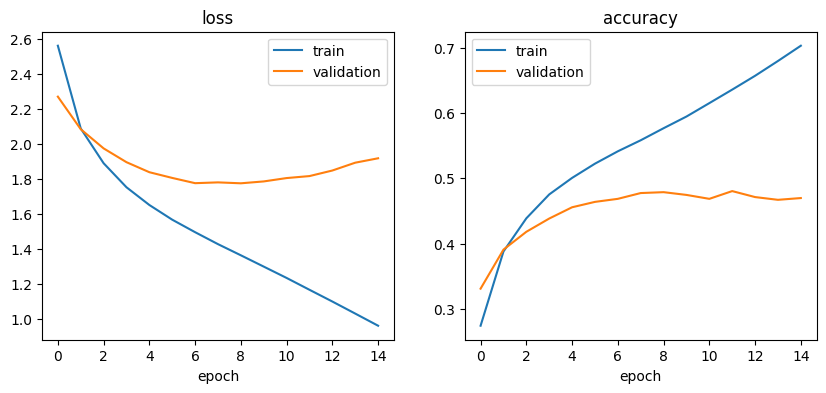

Final validation accuracy: 0.4698
Validation perplexity: 6.82


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for i, metric in enumerate(["loss", "accuracy"]):
    ax[i].plot(history.history[metric], label="train")
    ax[i].plot(history.history["val_" + metric], label="validation")
    ax[i].set_title(metric)
    ax[i].set_xlabel("epoch")
    ax[i].legend()
plt.show()
print(f"Final validation accuracy: {history.history['val_accuracy'][-1]:.4f}")
print(f"Validation perplexity: {np.exp(history.history['val_loss'][-1]):.2f}")

In [7]:
def generate(seed, length=300, temperature=0.5):
    out = seed.lower()
    for _ in range(length):
        x = np.array([[char_to_id[c] for c in out[-SEQ_LEN:]]])
        probs = model(x, training=False).numpy()[0].astype("float64")
        probs = np.exp(np.log(probs + 1e-9) / temperature)
        probs /= probs.sum()
        out += chars[np.random.choice(len(chars), p=probs)]
    return out


seed = text[1000:1000 + SEQ_LEN]
for t in [0.2, 0.5, 1.0]:
    print(f"--- temperature {t} ---")
    print(generate(seed, temperature=t))
    print()

--- temperature 0.2 ---


second citizen:
would you proceed especition of the people,
have when you to do king, and to the godsen sone to the gods
be spire of the people,
i was to have so make a most not
be good for the people,
i have so sweat marcius shall be the state,
i was of your wornd of his childed with his deeps,
which have shead my friends and to clamber 

--- temperature 0.5 ---


second citizen:
would you proceed especion of some.

gloucester:
i will we are solesed, and i country with suin,
though i be rease for your haves and trungly bread's.

volumnia:
down that not send of their forthing of your would
do peace, where it he did confeidery
what i have will not the great extime to cannot
be it lose them not
there 

--- temperature 1.0 ---


second citizen:
would you proceed especition.

lady anne:
sir, to buk kewell say 'the gods be surperies worth thy love
you those off, knet us kis,
caule to sue have do so.

menenius:
first if it?
ghou, itus their infection of your a tregl their furtent
a
brofive but, first, were affects name 'em: i canse that in the ataiss his diesing str

